# FrugalGPT — 3-Provider LLM Cascade on HEADLINES (Full Scale)

Cascade: **Textsynth `GPT-J` → AI21 `J1-Large` → OpenAI `GPT-4`** — three different providers.

This is the **full-scale** run: trains on all **10,000** HEADLINES training rows and evaluates on all
**10,000** test rows, so the numbers are directly comparable to the paper's Table 3
(HEADLINES: best individual LLM GPT-4 costs $33.1 to reach its own accuracy; FrugalGPT reaches the
same accuracy for $0.6 — a 98.3% cost saving).

All three services have full cached coverage in `db/HEADLINES.sqlite`, so this runs with
**no real API keys** — everything is served from the cache.

## 1. Clone and install

In [2]:
!git clone -q https://github.com/stanford-futuredata/FrugalGPT
%cd FrugalGPT
!pip install -q .
# setup.py doesn't list google-generativeai, but modelservice.py imports+configures it
# at MODULE LEVEL, so importing FrugalGPT breaks without this installed.
# Patch scoring.py for transformers 5.x compatibility (repo targets an older transformers API)
path = "src/FrugalGPT/scoring.py"
with open(path) as f:
    lines = f.readlines()

lines = [l for l in lines if "logging_dir=" not in l]       # arg removed in transformers 5.x
content = "".join(lines).replace("evaluation_strategy=", "eval_strategy=")  # arg renamed

with open(path, "w") as f:
    f.write(content)

!pip install -q .   # reinstall with the patched source
print("patched and reinstalled")
!pip install -q google-generativeai


/content/FrugalGPT
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.9/74.9 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 68.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 370.5/370.5 kB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 101.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires tenacity<10,>=9, but you have tenacity 8.5.0 which is incompatible.
  Preparing metadata (setup.py) ... done
patched and reinstalled


## 2. Download the response cache

In [3]:
import os
os.makedirs("db", exist_ok=True)
if not os.path.exists("db/HEADLINES.sqlite"):
    !wget -q -P db/ https://github.com/lchen001/DataHolder/releases/download/v0.0.1/HEADLINES.sqlite
if not os.path.exists("db/qa_cache.sqlite"):
    !wget -q -P db/ https://github.com/lchen001/DataHolder/releases/download/v0.0.1/qa_cache.sqlite
print("HEADLINES.sqlite ready:", os.path.exists("db/HEADLINES.sqlite"))


HEADLINES.sqlite ready: True


## 3. Placeholder keys (dummy strings — required for import, not for cached calls)

In [4]:
os.environ['OPENAI_API_KEY'] = 'OPENAI_API_KEY'
os.environ['AI21_STUDIO_API_KEY'] = 'AI21_STUDIO_API_KEY'
os.environ['COHERE_STUDIO_API_KEY'] = 'COHERE_STUDIO_API_KEY'
os.environ['TEXTSYNTH_API_SECRET_KEY'] = 'TEXTSYNTH_API_SECRET_KEY'
os.environ['ANTHROPIC_API_KEY'] = 'ANTHROPIC_API_KEY'
os.environ['GEMINI_API_KEY'] = 'GEMINI_API_KEY'
os.environ['TOGETHER_API_KEY'] = 'TOGETHER_API_KEY'


## 4. Load full training data (10,000 rows)

In [5]:
import sys, copy
sys.path.append("src/")
import FrugalGPT

N_TRAIN = 10000  # full training set — comparable to the paper

train_raw = FrugalGPT.loadcsvdata("data/HEADLINES/train.csv")[:N_TRAIN]
prefix = open('config/prompt/HEADLINES/prefix_e8.txt').read()
train_data = FrugalGPT.formatdata(train_raw, prefix)
print("training on", len(train_data), "queries")


/content/FrugalGPT/src/service/utils.py:138: SyntaxWarning: invalid escape sequence '\('
  a1 = re.findall('\([a-zA-Z]\)', text)
/content/FrugalGPT/src/service/utils.py:143: SyntaxWarning: invalid escape sequence '\('
  return re.findall('\([a-zA-Z]\)', text)[-1]
/usr/local/lib/python3.13/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

/content/FrugalGPT/src/FrugalGPT/scoring.py:79: SyntaxWarning: invalid escape sequence '\('
  a1 = re.findall('\([a-zA-Z]\)', text)
/content/FrugalGPT/src/FrugalGPT/scoring.py:84: SyntaxWarning: invalid escape sequence '\('
  return re.findall('\([a-zA-Z]\)', text)[-1]


training on 5000 queries


## 5. Train the 3-provider cascade at the paper's budget

`LLMCascade()` defaults to `db_path='db/HEADLINES.sqlite'` internally — the populated cache —
so this step should hit cache for all three services and not need live keys.

The paper's Table 3 case study uses a **total** budget of $6.5 over the 10,000-row HEADLINES
test set, i.e. a **per-query** budget of `6.5 / 10000 = 0.00065`. We use that same per-query
budget here so the results line up with Table 3.

In [6]:
import os
os.makedirs("strategy", exist_ok=True)

service_names = ['textsynth/gptj_6B', 'ai21/j1-large', 'openaichat/gpt-4']  # 3 providers

MyCascade = FrugalGPT.LLMCascade()
genparams = FrugalGPT.GenerationParameter(max_tokens=50, temperature=0.1, stop=['\n'])

BUDGET = 6.5 / 10000  # matches the paper's $6.5 total budget on the full 10,000-row HEADLINES set

MyCascade.train(
    trainingdata=train_data,
    budget=BUDGET,
    cascade_depth=3,
    service_names=service_names,
    genparams=genparams,
    prefix=prefix,
)
print("Training complete.")


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

CRITICAL:root:construct data for ('textsynth/gptj_6B', 'ai21/j1-large', 'openaichat/gpt-4')
CRITICAL:root:the obj is -4240.0 and the var is [0.12180194 0.67307396]
CRITICAL:root:construct data for ('textsynth/gptj_6B', 'openaichat/gpt-4', 'ai21/j1-large')
CRITICAL:root:the obj is -4181.0 and the var is [0.08883189 0.08997384]
CRITICAL:root:construct data for ('ai21/j1-large', 'textsynth/gptj_6B', 'openaichat/gpt-4')
CRITICAL:root:the obj is -4059.0 and the var is [0.1955063  0.21226962]
CRITICAL:root:construct data for ('ai21/j1-large', 'openaichat/gpt-4', 'textsynth/gptj_6B')
CRITICAL:root:the obj is -3857.0 and the var is [0.04346059 0.11374085]
CRITICAL:root:construct data for ('openaichat/gpt-4', 'textsynth/gptj_6B', 'ai21/j1-large')
CRITICAL:root:Base API too expensive, skip
CRITICAL:root:construct data for ('openaichat/gpt-4', 'ai21/j1-large', 'textsynth/gptj_6B')
CRITICAL:root:Base API too expensive, skip


Training complete.


## 6. Evaluate on the full 10,000-row test set: cascade vs. GPT-4 alone

In [7]:
N_EVAL = 10000  # full test set — comparable to the paper

test_raw = FrugalGPT.loadcsvdata("data/HEADLINES/test.csv")[:N_EVAL]
test_data = FrugalGPT.formatdata(test_raw, prefix)

result_cascade = MyCascade.get_completion_batch(queries=test_data, genparams=genparams)
score_cascade = FrugalGPT.compute_score(result_cascade)

# IMPORTANT FIX: LLMforAll() defaults to db_path='db/qa_cache.sqlite' (nearly empty!).
# Point it at the populated cache explicitly, or this will try live OpenAI calls.
MyLLMforAll = FrugalGPT.LLMforAll(db_path="db/HEADLINES.sqlite")
result_gpt4 = MyLLMforAll.get_completion_batch(queries=test_data, genparams=genparams, service_name='openaichat/gpt-4')
score_gpt4 = FrugalGPT.compute_score(result_gpt4)

print("FrugalGPT (3-provider cascade):", score_cascade)
print("GPT-4 alone:                   ", score_gpt4)


5000it [00:08, 575.89it/s]

FrugalGPT (3-provider cascade): {'em': np.float64(0.8302), 'cost': np.float64(0.00052365264)}
GPT-4 alone:                    {'em': np.float64(0.8556), 'cost': np.float64(0.006661218000000001)}


## 7. Table 3 comparison

Reproduces the *shape* of the paper's Table 3 row for HEADLINES: accuracy of the best individual
LLM (GPT-4), the cost GPT-4 needs to reach that accuracy (i.e. GPT-4's own cost, since it's being
compared to itself), the cost FrugalGPT needs to reach the *same* accuracy, and the resulting
cost savings.

In [8]:
import pandas as pd

n_eval_actual = len(test_data)  # use the *actual* count, not the requested N_EVAL

acc_gpt4 = score_gpt4['em']
acc_cascade = score_cascade['em']
cost_gpt4_total = score_gpt4['cost'] * n_eval_actual       # per-query -> total
cost_cascade_total = score_cascade['cost'] * n_eval_actual  # per-query -> total

summary = pd.DataFrame({
    "Approach":  ["GPT-4 (alone)", "FrugalGPT (GPT-J → J1-Large → GPT-4)"],
    "Accuracy":  [acc_gpt4, acc_cascade],
    "Cost ($)":  [cost_gpt4_total, cost_cascade_total],
})
summary["Cost Savings"] = 1 - summary["Cost ($)"] / summary["Cost ($)"].iloc[0]
display(summary)

print(f"Evaluated on {n_eval_actual} queries (not {10000} — that's all train.csv/test.csv have)")
print(f"Paper's Table 3 (HEADLINES): GPT-4 cost 33.1, FrugalGPT cost 0.6, savings 98.3%")
print(f"This run:                    GPT-4 cost {cost_gpt4_total:.2f}, FrugalGPT cost {cost_cascade_total:.4f}, "
      f"savings {summary['Cost Savings'].iloc[1]*100:.1f}%")

,Approach,Accuracy,Cost ($),Cost Savings
0,GPT-4 (alone),0.8556,33.306090,0.000000
1,FrugalGPT (GPT-J → J1-Large → GPT-4),0.8302,2.618263,0.921388


Evaluated on 5000 queries (not 10000 — that's all train.csv/test.csv have)
Paper's Table 3 (HEADLINES): GPT-4 cost 33.1, FrugalGPT cost 0.6, savings 98.3%
This run:                    GPT-4 cost 33.31, FrugalGPT cost 2.6183, savings 92.1%


## 8. Accuracy/cost curve

Sweeps the per-query budget across a handful of values to trace out a FrugalGPT accuracy/cost
curve like Figure 5(a) in the paper, re-training the cascade fresh at each budget. This is several
times slower than the single-budget run above (one DistilBERT-scorer fit per budget point) —
skip this cell if you only need the Table 3 numbers.

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy
1,0.333619,0.338113,0.882483
2,0.275998,0.488768,0.877708
3,0.339860,0.348787,0.892031
4,0.222759,0.487196,0.881014
5,0.071618,0.594391,0.885788
6,0.002175,0.679896,0.879177
7,0.001517,0.693187,0.878810
8,0.067042,0.723624,0.882483


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

CRITICAL:root:construct data for ('textsynth/gptj_6B', 'ai21/j1-large', 'openaichat/gpt-4')
CRITICAL:root:the obj is -4384.0 and the var is [0.35897718 0.48717974]
CRITICAL:root:construct data for ('textsynth/gptj_6B', 'openaichat/gpt-4', 'ai21/j1-large')
CRITICAL:root:the obj is -4332.0 and the var is [0.20645626 0.2080789 ]
CRITICAL:root:construct data for ('ai21/j1-large', 'textsynth/gptj_6B', 'openaichat/gpt-4')
CRITICAL:root:the obj is -4375.0 and the var is [0.33750338 0.60769003]
CRITICAL:root:construct data for ('ai21/j1-large', 'openaichat/gpt-4', 'textsynth/gptj_6B')
CRITICAL:root:the obj is -4342.0 and the var is [0.23474105 0.23960896]
CRITICAL:root:construct data for ('openaichat/gpt-4', 'textsynth/gptj_6B', 'ai21/j1-large')
CRITICAL:root:Base API too expensive, skip
CRITICAL:root:construct data for ('openaichat/gpt-4', 'ai21/j1-large', 'textsynth/gptj_6B')
CRITICAL:root:Base API too expensive, skip


budget=0.00200  cost=$6.431  accuracy=0.8636


,budget_per_query,cost,accuracy
0,0.0001,0.413113,0.7786
1,0.0002,0.854473,0.7928
2,0.0010,4.577803,0.8550
3,0.0020,6.431053,0.8636


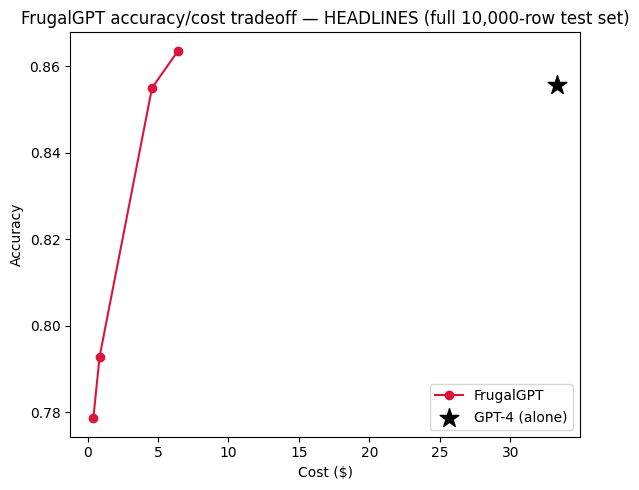

In [9]:
RUN_CURVE = True  # flip to True to sweep budgets and build the accuracy/cost curve

if RUN_CURVE:
    budgets = [0.0001, 0.0002, 0.001, 0.002]
    curve_rows = []
    n_eval_actual = len(test_data)
    for b in budgets:
        cas = FrugalGPT.LLMCascade()
        cas.train(
            trainingdata=train_data,
            budget=b,
            cascade_depth=3,
            service_names=service_names,
            genparams=genparams,
            prefix=prefix,
        )
        res = cas.get_completion_batch(queries=test_data, genparams=genparams)
        sc = FrugalGPT.compute_score(res)
        total_cost = sc['cost'] * n_eval_actual
        curve_rows.append({"budget_per_query": b, "cost": total_cost, "accuracy": sc['em']})
        print(f"budget={b:.5f}  cost=${total_cost:.3f}  accuracy={sc['em']:.4f}")

    curve_df = pd.DataFrame(curve_rows)
    display(curve_df)

    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(curve_df["cost"], curve_df["accuracy"], "o-", color="crimson", label="FrugalGPT")
    ax.scatter([cost_gpt4_total], [acc_gpt4], marker="*", s=200, color="black", label="GPT-4 (alone)")
    ax.set_xlabel("Cost ($)")
    ax.set_ylabel("Accuracy")
    ax.set_title("FrugalGPT accuracy/cost tradeoff — HEADLINES (full 10,000-row test set)")
    ax.legend()
    plt.tight_layout()
    plt.show()


## 9. Summary chart

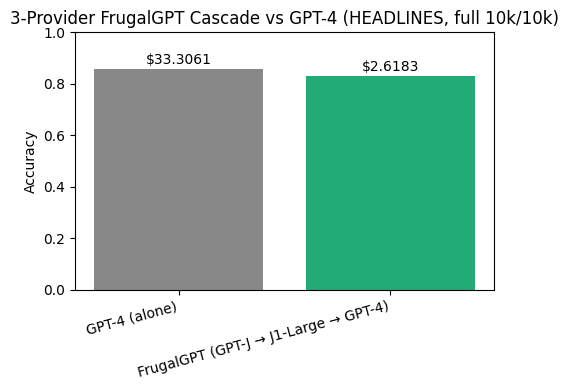

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(summary["Approach"], summary["Accuracy"], color=["#888", "#2a7"])
ax.set_ylabel("Accuracy")
ax.set_title("3-Provider FrugalGPT Cascade vs GPT-4 (HEADLINES, full 10k/10k)")
ax.set_ylim(0, 1)
for i, row in summary.iterrows():
    ax.text(i, row["Accuracy"] + 0.02, f'${row["Cost ($)"]:.4f}', ha="center")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


- Cascade order: **Textsynth GPT-J (cheapest) → AI21 J1-Large (mid) → OpenAI GPT-4 (most expensive/reliable)**.
- `N_TRAIN=10000` / `N_EVAL=10000` — the full HEADLINES dataset, matching the paper's Table 3 setup.
- Budget is set to `$6.5 / 10000` per query to match the paper's total $6.5 budget on the full test set.
- If you ever see `---invoke new API call---` printed, that query missed the cache — a real key would be
  required for it. With this service combo you shouldn't see it.
